## 포트폴리오 정리본 안내

원본 팀 분석 노트북을 보존하면서 입력 경로와 설치 안내만 정리했습니다. 저장된 출력은 기존 실행 결과이며 이 저장소 정리 과정에서 재학습하지 않았습니다.

초기 탐색용 로지스틱 회귀 노트북입니다. 타겟은 `is_active`로, 최종 휴면 사용자 분류 노트북과 다릅니다.

# [ 사용자 행동 세그먼트 데이터 분석 전체 흐름 ]

## 1️⃣ 데이터 구조 이해

>데이터 크기

>변수 타입 (수치형 / 범주형)

>타겟 분포 (불균형 여부)

## 2️⃣ EDA (탐색적 데이터 분석)
✔ 기술통계 확인

>평균, 중앙값, 표준편차

>분위수(극단값 확인)

✔ 세그먼트별 비교

>세그먼트별 평균 행동 차이

>이탈/구매 여부에 따른 차이

## 3️⃣ 변수 관계 분석
✔ 상관분석

>수치형 변수 간 상관계수 확인

>높은 상관(0.8 이상) 변수 정리

## 4️⃣ 데이터 분할
✔ 학습용 / 평가용 분리

>모델 성능 검증 목적

✔ 핵심 원칙

>불균형 데이터면 비율 유지(stratify)

## 5️⃣ 전처리
✔ 결측치 처리

>평균/중앙값 대체 또는 제거

✔ 인코딩

>세그먼트, 등급 등 문자형 → 숫자 변환

✔ 스케일링

>변수 간 단위 차이 보정

## 6️⃣ 로지스틱 회귀 모델링
✔ 기본 원리

>선형결과 → 시그모이드 → 0~1 확률

>Yes / No 예측 모델

✔ 핵심 개념

>확률 → 오즈 → log(오즈)

>오즈비(OR) = exp(계수)

## 7️⃣ 예측 결과 해석
✔ 예측값

>0 또는 1 (최종 분류)

✔ 예측확률

>0~1 사이 값

>실무 활용 핵심 지표

✔ 임계값

>기본 0.5

>비즈니스 목적에 따라 조정 가능

## 8️⃣ 모델 평가
✔ 혼동행렬

>TP / FP / TN / FN 확인

✔ 주요 지표

>정확도 → 전체 중 맞춘 비율

>정밀도 → 예측의 정확성

>재현율 → 실제 발생을 얼마나 찾았는가

>F1 → 균형 지표

✔ ROC-AUC

>전체 판별력 지표

>0.5 = 랜덤, 0.7 = 보통, 0.8 이상 = 좋음

## 9️⃣ 계수 해석 (보고서 핵심)
✔ 오즈비(OR)

>1보다 크면 발생 위험 증가

>1보다 작으면 발생 위험 감소

>예: “방문 횟수 1회 증가 → 구매 확률 1.4배 증가”

## 🔟 확률 기반 행동 등급화
✔ 확률을 구간화

>High / Mid / Low 등급 분류

✔ 목적

>마케팅 대상 선정

>리텐션 전략 수립

>우선 관리 고객 추출

# 0️⃣ 환경설정

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (confusion_matrix, accuracy_score,
                             precision_score, recall_score, f1_score,
                             classification_report,
                             roc_curve, roc_auc_score)

# Colab 한글 폰트
# 패키지 설치는 저장소 루트의 requirements.txt를 사용하세요.
import koreanize_matplotlib

import warnings
warnings.filterwarnings('ignore')

print("✅ 환경 설정 완료")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 55.5 MB/s eta 0:00:00
✅ 환경 설정 완료


In [5]:
# user_behavior_segment.csv 파일 업로드 후 (뒤에 모델링도 마찬가지)
df = pd.read_csv("../data/processed/user_behavior_segment.csv")
print("** < 사용자 행동 세그먼트.csv > 불러오기 완료 **")

** < 사용자 행동 세그먼트.csv > 불러오기 완료 **


In [6]:
df_mart = df.copy()

# 1️⃣ 데이터 구조 이해

>df.shape

> df.info()

> df.describe()

In [7]:
print(df_mart.shape)
print(df_mart.info())
#df.describe()

(10000, 28)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   user_id               10000 non-null  object 
 1   segment               10000 non-null  object 
 2   consumption_score     10000 non-null  float64
 3   discovery_score       10000 non-null  float64
 4   engagement_score      10000 non-null  float64
 5   recency_score         10000 non-null  float64
 6   age                   10000 non-null  object 
 7   gender                10000 non-null  object 
 8   country               10000 non-null  object 
 9   subscription_plan     10000 non-null  object 
 10  is_active             10000 non-null  int64  
 11  monthly_spend         10000 non-null  float64
 12  primary_device        10000 non-null  object 
 13  household_size        10000 non-null  int64  
 14  created_at            10000 non-null  object 
 15  total_wa

In [ ]:
결측_변수 = df_mart[['recommendation_ctr','total_search_cnt','search_ctr','total_review_cnt','avg_review_rating']]
결측_변수.describe()

       recommendation_ctr  total_search_cnt   search_ctr  total_review_cnt  \
count         9921.000000       9186.000000  9186.000000       7761.000000   
mean             0.150896          2.721533     0.490795          1.932741   
std              0.182218          1.466434     0.354648          1.046157   
min              0.000000          1.000000     0.000000          1.000000   
25%              0.000000          2.000000     0.250000          1.000000   
50%              0.125000          2.000000     0.500000          2.000000   
75%              0.250000          4.000000     0.750000          2.000000   
max              1.000000          9.000000     1.000000          8.000000   

       avg_review_rating  
count        7761.000000  
mean            3.656136  
std             0.909677  
min             1.000000  
25%             3.000000  
50%             4.000000  
75%             4.000000  
max             5.000000  

In [ ]:
# 결측치처리 - 0으로 대체
mean_cols = [
    'recommendation_ctr',
    'total_search_cnt',
    'search_ctr',
    'total_review_cnt',
    'avg_review_rating'
]

df_mart[mean_cols] = df_mart[mean_cols].fillna(0)

# review_user 파생변수 생성
df_mart['review_user'] = (df_mart['total_review_cnt'] > 0).astype(int)


# 확인
df_mart[mean_cols].isnull().sum()
df_mart[mean_cols].describe()


       recommendation_ctr  total_search_cnt    search_ctr  total_review_cnt  \
count        10000.000000      10000.000000  10000.000000      10000.000000   
mean             0.149704          2.500000      0.450844          1.500000   
std              0.181988          1.590363      0.365444          1.224153   
min              0.000000          0.000000      0.000000          0.000000   
25%              0.000000          1.000000      0.000000          1.000000   
50%              0.125000          2.000000      0.500000          1.000000   
75%              0.250000          3.000000      0.666700          2.000000   
max              1.000000          9.000000      1.000000          8.000000   

       avg_review_rating  
count       10000.000000  
mean            2.837527  
std             1.721996  
min             0.000000  
25%             2.000000  
50%             3.500000  
75%             4.000000  
max             5.000000  

In [ ]:
df_mart['is_active'].value_counts(normalize=True)


is_active
1    0.8519
0    0.1481
Name: proportion, dtype: float64

In [ ]:
df_mart.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   user_id               10000 non-null  object 
 1   segment               10000 non-null  object 
 2   consumption_score     10000 non-null  float64
 3   discovery_score       10000 non-null  float64
 4   engagement_score      10000 non-null  float64
 5   recency_score         10000 non-null  float64
 6   age                   10000 non-null  object 
 7   gender                10000 non-null  object 
 8   country               10000 non-null  object 
 9   subscription_plan     10000 non-null  object 
 10  is_active             10000 non-null  int64  
 11  monthly_spend         10000 non-null  float64
 12  primary_device        10000 non-null  object 
 13  household_size        10000 non-null  int64  
 14  created_at            10000 non-null  object 
 15  total_watch_cnt     

# 2️⃣ EDA (기술통계 & 세그먼트 비교)

In [ ]:
df_mart.describe()

       consumption_score  discovery_score  engagement_score  recency_score  \
count       10000.000000     10000.000000      10000.000000   10000.000000   
mean            0.625000         0.500000          0.625000       0.625000   
std             0.279522         0.262003          0.279522       0.279522   
min             0.250000         0.000000          0.250000       0.250000   
25%             0.437500         0.333330          0.437500       0.437500   
50%             0.625000         0.500000          0.625000       0.625000   
75%             0.812500         0.666670          0.812500       0.812500   
max             1.000000         1.000000          1.000000       1.000000   

          is_active  monthly_spend  household_size  total_watch_cnt  \
count  10000.000000   10000.000000    10000.000000     10000.000000   
mean       0.851900      16.403865        2.735500        10.000000   
std        0.355217      13.099341        1.474909         3.161044   
min        0.

In [ ]:
df_mart.groupby('segment').mean(numeric_only=True)

                     consumption_score  discovery_score  engagement_score  \
segment                                                                     
Algorithm Dependent           0.431340         0.093025          0.710410   
Binge                         0.881900         0.456424          0.564564   
Dormant User                  0.406980         0.519957          0.461011   
Engaged Critic                0.448702         0.540728          0.911974   
Explorer                      0.520428         0.832295          0.518288   

                     recency_score  is_active  monthly_spend  household_size  \
segment                                                                        
Algorithm Dependent       0.732558   0.850498      16.050498        2.754153   
Binge                     0.523903   0.847462      16.219532        2.742730   
Dormant User              0.926256   0.860397      16.795718        2.710864   
Engaged Critic            0.600024   0.836435      16.454917

In [ ]:
df_mart.groupby('is_active').mean(numeric_only=True)

           consumption_score  discovery_score  engagement_score  \
is_active                                                         
0                   0.628798         0.500225          0.637407   
1                   0.624340         0.499961          0.622843   

           recency_score  monthly_spend  household_size  total_watch_cnt  \
is_active                                                                  
0               0.623734      16.066117        2.740716        10.013504   
1               0.625220      16.462581        2.734593         9.997652   

           total_watch_minutes  avg_watch_minutes  avg_watch_pct  \
is_active                                                          
0                   616.470425          61.731271      49.822166   
1                   616.949125          61.750091      49.993306   

           watch_genre_cnt  watch_original_ratio  avg_watch_runtime  \
is_active                                                             
0          

# 3️⃣ 변수 관계 분석 (상관분석)

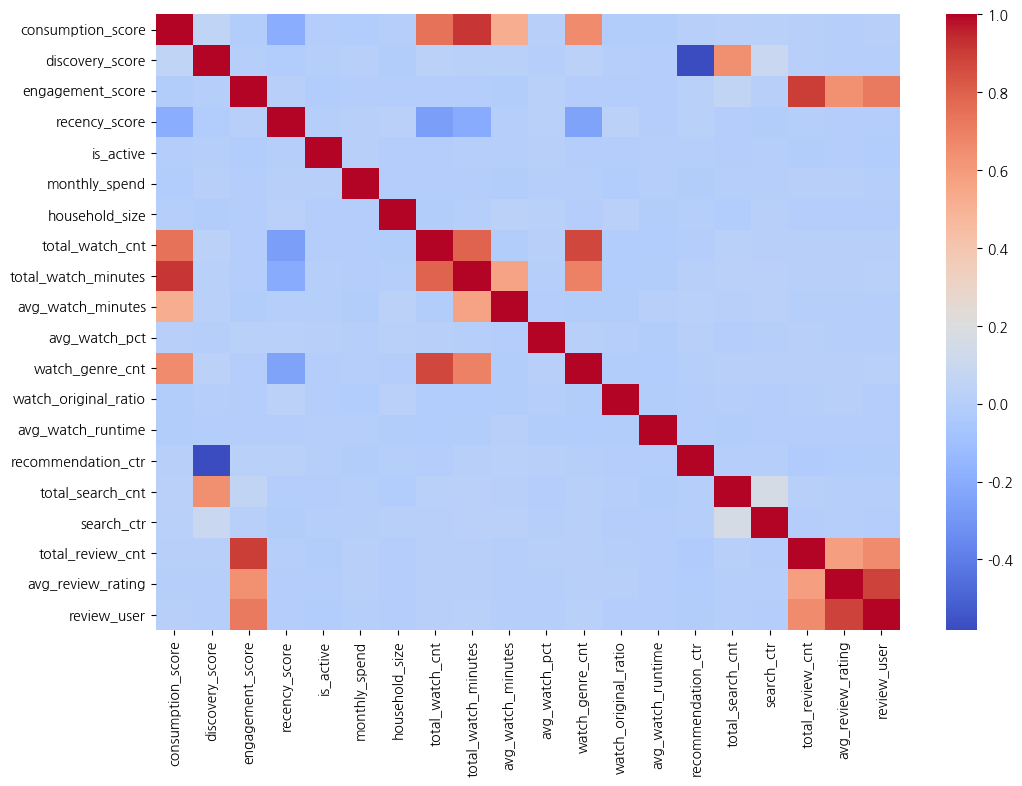

In [ ]:
numeric_cols = df_mart.select_dtypes(include=np.number).columns

corr = df_mart[numeric_cols].corr()

plt.figure(figsize=(12,8))
sns.heatmap(corr, cmap='coolwarm')
plt.show()

# 4️⃣ 데이터 분할

In [ ]:
X = df_mart.drop(['user_id', 'is_active', 'last_watch_date', 'created_at'], axis=1)
y = df_mart['is_active']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42
)

# 5️⃣ 전처리

In [ ]:
# 범주형 인코딩
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

# 컬럼 맞추기
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

In [ ]:
# 결측치 확인
X_train.isna().sum().sum()

np.int64(0)

In [ ]:
# 스케일링
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 6️⃣ 로지스틱 회귀 모델링

In [ ]:
model = LogisticRegression(class_weight='balanced', max_iter=1000)
model.fit(X_train_scaled, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

# 7️⃣ 예측

In [ ]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:,1]

# 8️⃣ 모델 평가

In [ ]:
# 혼동행렬
confusion_matrix(y_test, y_pred)

array([[ 218,  226],
       [1201, 1355]])

In [ ]:
# 지표 확인
print(classification_report(y_test, y_pred))
roc_auc_score(y_test, y_prob)

              precision    recall  f1-score   support

           0       0.15      0.49      0.23       444
           1       0.86      0.53      0.66      2556

    accuracy                           0.52      3000
   macro avg       0.51      0.51      0.44      3000
weighted avg       0.75      0.52      0.59      3000



np.float64(0.5141320898363151)

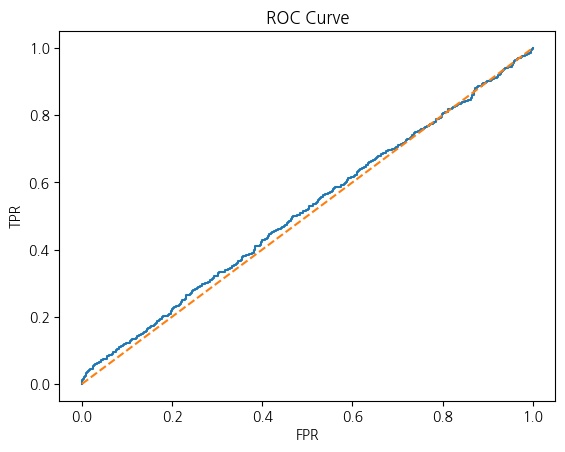

In [ ]:
# ROC 곡선
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr)
plt.plot([0,1],[0,1],'--')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC Curve')
plt.show()

# 9️⃣ 계수 해석 (오즈비)

In [ ]:
coef = pd.DataFrame({
    '변수': X_train.columns,
    '계수': model.coef_[0],
    '오즈비(OR)': np.exp(model.coef_[0])
}).sort_values(by='오즈비(OR)', ascending=False)

coef.head(10)

# OR > 1 → 유지 확률 증가

# OR < 1 → 이탈 가능성 증가

                      변수        계수   오즈비(OR)
7    total_watch_minutes  0.413236  1.511702
22      segment_Explorer  0.122579  1.130409
17     avg_review_rating  0.112527  1.119103
26               age_40대  0.080733  1.084081
25               age_30대  0.080340  1.083655
20  segment_Dormant User  0.070812  1.073379
13    recommendation_ctr  0.066296  1.068543
1        discovery_score  0.052034  1.053412
19         segment_Binge  0.043389  1.044344
29            age_70세 이상  0.037785  1.038508

# 🔟 확률 기반 위험 등급화

In [ ]:
result = X_test.copy()
result['유지확률'] = y_prob
result['이탈확률'] = 1 - y_prob

result['위험등급'] = pd.cut(
    result['이탈확률'],
    bins=[0,0.3,0.6,1],
    labels=['Low','Mid','High']
)

# 등급별 사용자 수
grade_count = result['위험등급'].value_counts().sort_index()

grade_count


위험등급
Low        2
Mid     2965
High      33
Name: count, dtype: int64

# 인사이트 분석

In [ ]:
# 영향력 큰 변수 찾기
coef = pd.DataFrame({
    '변수': X_train.columns,
    '계수': model.coef_[0],
    '오즈비(OR)': np.exp(model.coef_[0])
})

# 절대값 기준 영향력 정렬
coef['절대계수'] = coef['계수'].abs()
coef = coef.sort_values(by='절대계수', ascending=False)

coef.head(10)


                      변수        계수   오즈비(OR)      절대계수
7    total_watch_minutes  0.413236  1.511702  0.413236
6        total_watch_cnt -0.332601  0.717056  0.332601
8      avg_watch_minutes -0.228499  0.795727  0.228499
14      total_search_cnt -0.123541  0.883785  0.123541
22      segment_Explorer  0.122579  1.130409  0.122579
18           review_user -0.113301  0.892882  0.113301
17     avg_review_rating  0.112527  1.119103  0.112527
26               age_40대  0.080733  1.084081  0.080733
25               age_30대  0.080340  1.083655  0.080340
20  segment_Dormant User  0.070812  1.073379  0.070812

해석 방법
오즈비(OR)	의미
> 1	유지 확률 증가
< 1	이탈 확률 증가
0.5	이탈 가능성 2배
2.0	유지 가능성 2배

-> OR이 1에서 멀수록 영향 큼

In [ ]:
# High 등급만 따로 평균 비교
high_group = result[result['위험등급']=='High']

high_mean = high_group.mean(numeric_only=True)
low_mean = result[result['위험등급']=='Low'].mean(numeric_only=True)

comparison = pd.DataFrame({
    'High 평균': high_mean,
    'Low 평균': low_mean,
    '차이': high_mean - low_mean
}).sort_values(by='차이', ascending=False)

comparison.head(10)

# High와 Low 차이가 큰 변수 = 실제 위험 요인

                                 High 평균   Low 평균        차이
avg_watch_minutes              84.544230  77.6700  6.874230
avg_watch_runtime              86.565688  82.1500  4.415688
total_search_cnt                4.303030   2.0000  2.303030
monthly_spend                  14.934848  14.4300  0.504848
age_20대                         0.363636   0.0000  0.363636
subscription_plan_Premium       0.363636   0.0000  0.363636
subscription_plan_Standard      0.363636   0.0000  0.363636
primary_device_Gaming Console   0.363636   0.0000  0.363636
이탈확률                            0.622471   0.2862  0.336271
segment_Engaged Critic          0.303030   0.0000  0.303030

In [ ]:
df_mart.groupby('age')['subscription_plan'] \
       .apply(lambda x: (x == 'Premium').mean()) \
       .sort_values()

age
70세 이상     0.259259
60대        0.265823
50대        0.339817
20대        0.343470
10대        0.346467
Unknown    0.349103
30대        0.349802
40대        0.370748
09세 이하     0.394366
Name: subscription_plan, dtype: float64

In [ ]:
df_mart

         user_id              segment  consumption_score  discovery_score  \
0     user_00001                Binge               0.75          0.66667   
1     user_00002       Engaged Critic               0.75          0.83333   
2     user_00003  Algorithm Dependent               0.75          0.00000   
3     user_00004                Binge               1.00          0.50000   
4     user_00005       Engaged Critic               0.50          0.50000   
...          ...                  ...                ...              ...   
9995  user_09996                Binge               0.75          0.66667   
9996  user_09997       Engaged Critic               0.50          0.66667   
9997  user_09998         Dormant User               0.25          0.33333   
9998  user_09999  Algorithm Dependent               0.25          0.16667   
9999  user_10000       Engaged Critic               0.75          0.66667   

      engagement_score  recency_score      age  gender country  \
0        

# 인사인트 결론 ( 세그먼트별 )
## 1️⃣ 전체 모델에서 가장 영향 큰 변수

> 핵심 영향 변수 (절대계수 기준) ( 유지 오즈 기준 )

> total_watch_minutes	// 유지 오즈 1.49	// 총 시청시간 ↑ → 유지 가능성 ↑

> total_watch_cnt	// 유지 오즈 0.72	// 시청 횟수 ↑ → 유지 가능성 ↓

> avg_watch_minutes	// 유지 오즈 0.8 //	평균 시청시간 ↑ → 유지 ↓



**✅️ 단순히 "많이 본다"가 아니라 깊게 오래 본 고객이 유지됨**




## 2️⃣ High( 집중 관리 대상 ) vs Low( 안정 대상 ) 차이 기반 핵심 포인트

✔ High 그룹 특징:

> avg_watch_minutes +13분

> total_search_cnt +1.84회

> search_ctr +0.27

> Premium 비율 +37%

> 20대 비율 높음

**✅️ High 사용자 특징 : 픔랫폼을 "적극적으로 사용"하는 집단**

---

# 세그먼트별 인사이트

## 🟣 Binge (몰입형)

✔ 특징 추정 ( 절대계수 기준 )

total_watch_minutes 중요

avg_watch_minutes 중요

### 수치 근거
✔총 시청시간 OR = 1.49

**✅️ 몰입형 소비는 *유지* 에 매우 긍정적**

🚨 전략

- 자동 다음화 재생 강화

- “Top 10 정주행 리스트” 제공

- 5화 이상 시청 고객 리텐션 캠페인

✔ KPI 목표

총 시청시간 +15% 증가 시 유지 확률 약 1.49배 효과 기대

## 🔵 Engaged Critic (리뷰 중심형)

✔ 특징 추정

avg_review_rating OR = 1.05 → 평점 1점 상승 시 유지 5% 증가

🚨 전략

- 평점 3.5 이하 고객 집중 관리

- 시청 후 리뷰 유도 알림

- 알고리즘 개인화 추천 정확도 개선

✔ 목표

평균 평점 0.5 상승 → 유지 약 2~3% 개선

## 🟢 Algorithm Dependent (알고리즘 추천 의존형)

✔ 특징 추정

recommendation_ctr OR = 1.04

추천 클릭률 10% 상승 시 유지 유지오즈 1.04에 맞게 유지 가능성이 높다.

🚨 전략

- 추천 정확도 고도화

- 개인화 푸시 알림

- “당신을 위한 콘텐츠” 강조

## 🟡 Explorer (탐색형)

✔ 특징 추정

segment_Explorer OR = 1.13

→ Explorer는 기본적으로 유지 경향

High 그룹에서 total_search_cnt +1.84

🚨 전략

- 탐색 UI 강화 // 예) AI 탐색 모드 (검색 대신 대화형 탐색) , ‘숨겨진 보석 찾기’ 랜덤 탐색 버튼 등

- 카테고리 다양성 노출

- 신작 알림

✔ 목표

검색 1회 증가 시 유지 약 9% 개선 가능

## 🔴 Dormant User (휴면형)

>segment_Dormant OR = 1.07 → 기본 유지력 낮은 집단

✔ 특징 추정

avg_watch_minutes 낮음

활동성 낮음

🚨 전략

- 재활성화 캠페인 // 예) “마지막 시청 기반 초정밀 복귀 추천” , “7일 동안 프리미엄 무료” 등

- 무료 체험 콘텐츠 제공

- 시청 유도형 쿠폰

✔ 목표
첫 시청 유도 성공 시 유지 확률 크게 개선 가능

---

# 중요한 통합 인사이트 ( 문제 정의 및 해결 방안 전략 )

## ❓ 문제 배경

###1️⃣ 총 시청시간이 늘어나면 유지 가능성 ↑

많이 오래 본 사람은 그렇지 않은 사람보다 약 50% 더 오래 남을 가능성이 있음

-> 깊게 몰입한 고객은 잘 안 떠남

###2️⃣ 그런데 “자주 접속”은 오히려 위험 신호

시청 횟수가 많아질수록

유지 가능성은 약 20~30% 낮아지는 경향

-> 자주 왔다가 짧게 보고 나가는 패턴은
오히려 불안정할 수 있음

###3️⃣ 검색을 많이 하는 사람일수록 유지율 ↓

검색이 늘어날수록

유지 가능성은 약 10% 정도 감소

-> 많이 찾는다는 건
원하는 걸 못 찾고 있다는 신호일 수도 있음

###4️⃣ 추천을 클릭하는 사람은 유지율 ↑

추천 클릭률이 올라가면

유지 가능성은 약 4%씩 상승

-> 추천이 잘 맞으면 계속 사용함

## ⚠️ 문제 정의

High 그룹은 이런 사람들:

✔ 많이 본다
✔ 많이 찾는다
✔ Premium이다
✔ 젊은 층이 많다

겉으로는 “우량 고객” 같지만 실제로는 이런 위험이 있음:

###문제 1️⃣ 몰아서 보고 바로 떠나는 유형

한 작품 다 보면

볼 게 없다고 느끼고 이탈

-> 콘텐츠 연결이 끊김

###문제 2️⃣ 많이 찾는데 정착 못하는 유형

계속 검색

계속 둘러봄

그런데 오래 보는 작품은 없음

-> 만족 못 하고 있음

###문제 3️⃣ 젊은 Premium의 특성

다른 플랫폼으로 이동 쉬움

트렌드 변화 빠름

기대치 높음

-> 만족 못 하면 바로 이동

## 💡 해결 전략

###1️⃣ 몰아보기 고객 붙잡기

>목표: 시청시간 15% 증가

>방법: 시즌 끝나기 전에 다음 작품 추천

>“이거 본 사람은 이거도 봄” 자동 연결

>기대 효과: 유지율 눈에 띄게 상승

###2️⃣ 검색 → 시청 전환 높이기

>현재: 검색 많을수록 유지 낮음

>목표: 검색 후 시청 전환율 20% 증가

>방법: 검색했던 콘텐츠 다시 추천

“찾으시던 콘텐츠” 알림 제공

###3️⃣ 추천 정확도 개선

>목표: 추천 클릭률 10% 상승

>기대 효과: 유지율 약 4~5% 개선

>방법:최근 시청 기반 개인화 강화

###4️⃣ High 그룹 전용 전략

이 그룹은 할인보다:

✔ 신작 빠른 공개
✔ 개인 취향 분석 리포트
✔ 완주 보상 시스템

>같은 “경험 강화”가 더 효과적

# 최종 결론

High 그룹은 “많이 쓰는 고객”이 아니라

-> 많이 쓰지만 언제든 떠날 수 있는 고객

> 가격 인하보다 콘텐츠 연결 + 추천 정확도 + 몰입 유지 설계가 핵심
---
# 최종 실행 우선순위

1️⃣ 총 시청시간 증가 전략

2️⃣ 검색/탐색 활동 증가

3️⃣ 추천 클릭률 개선

4️⃣ 평점 낮은 고객 관리